# Entrenamiento de detección de emociones con CNN

Importación de paquetes

In [8]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical


Variables del dataset

In [ ]:
DATASET_DIR = "dataset_processed"
IMG_SIZE = 32
MODEL_PATH = "model_results/cnn/cnn_emotion.h5"

CLASSES = sorted(os.listdir(os.path.join(DATASET_DIR, "train")))
print("Clases:", CLASSES)


Cargar imágenes (gris, 32x32) y combinarlas con los keypoints geométricos de MediaPipe

In [3]:
def load_split(split_name):
    keypoints_path = os.path.join(DATASET_DIR, f"{split_name}_keypoints.npz")
    kp_data = np.load(keypoints_path, allow_pickle=True)
    kp_features = kp_data["features"].astype("float32")
    kp_labels = kp_data["labels"]
    kp_filenames = kp_data["filenames"]

    split_dir = os.path.join(DATASET_DIR, split_name)

    X_img, y = [], []
    for label, fname in zip(kp_labels, kp_filenames):
        img = cv2.imread(os.path.join(split_dir, label, fname), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X_img.append(img)
        y.append(CLASSES.index(label))

    X_img = np.array(X_img, dtype="float32") / 255.0
    X_img = X_img.reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    X_geo = kp_features
    y = to_categorical(y, num_classes=len(CLASSES))
    return X_img, X_geo, y


X_train_img, X_train_geo, y_train = load_split("train")
X_test_img, X_test_geo, y_test = load_split("test")

print("Train:", X_train_img.shape, X_train_geo.shape, "Test:", X_test_img.shape, X_test_geo.shape)


Train: (36502, 32, 32, 1) (36502, 9) Test: (9182, 32, 32, 1) (9182, 9)


Definición de la CNN

In [4]:
image_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="image_input")
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(image_input)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)

geo_input = layers.Input(shape=(X_train_geo.shape[1],), name="geo_input")
g = layers.Dense(32, activation="relu")(geo_input)

combined = layers.Concatenate()([x, g])
combined = layers.Dense(64, activation="relu")(combined)
output = layers.Dense(len(CLASSES), activation="softmax")(combined)

model = models.Model(inputs=[image_input, geo_input], outputs=output)
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image_input (InputLayer)       [(None, 32, 32, 1)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 32, 32, 32)   320         ['image_input[0][0]']            
                                                                                                  
 max_pooling2d (MaxPooling2D)   (None, 16, 16, 32)   0           ['conv2d[0][0]']                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 16, 16, 64)   18496       ['max_pooling2d[0][0]']          
                                                                                              

Entrenamiento

In [5]:
history = model.fit(
    [X_train_img, X_train_geo], y_train,
    validation_split=0.1,
    epochs=30,
    batch_size=64,
)

test_loss, test_accuracy = model.evaluate([X_test_img, X_test_geo], y_test)
print("Accuracy en test:", test_accuracy)


Epoch 1/30
514/514 [==============================] - 5s 7ms/step - loss: 1.1798 - accuracy: 0.5082 - val_loss: 1.9366 - val_accuracy: 0.3144
Epoch 2/30
514/514 [==============================] - 3s 6ms/step - loss: 0.9918 - accuracy: 0.5967 - val_loss: 1.4510 - val_accuracy: 0.4744
Epoch 3/30
514/514 [==============================] - 3s 6ms/step - loss: 0.9402 - accuracy: 0.6179 - val_loss: 1.5227 - val_accuracy: 0.4643
Epoch 4/30
514/514 [==============================] - 3s 6ms/step - loss: 0.8966 - accuracy: 0.6353 - val_loss: 1.4937 - val_accuracy: 0.4766
Epoch 5/30
514/514 [==============================] - 3s 6ms/step - loss: 0.8558 - accuracy: 0.6565 - val_loss: 1.4198 - val_accuracy: 0.5001
Epoch 6/30
514/514 [==============================] - 3s 6ms/step - loss: 0.8186 - accuracy: 0.6737 - val_loss: 1.5514 - val_accuracy: 0.4322
Epoch 7/30
514/514 [==============================] - 3s 6ms/step - loss: 0.7802 - accuracy: 0.6896 - val_loss: 1.5296 - val_accuracy: 0.4736
Epoch 

Guardar el modelo entrenado y generar una gráfica de los resultados

Modelo guardado en model_results/cnn/cnn_emotion.keras


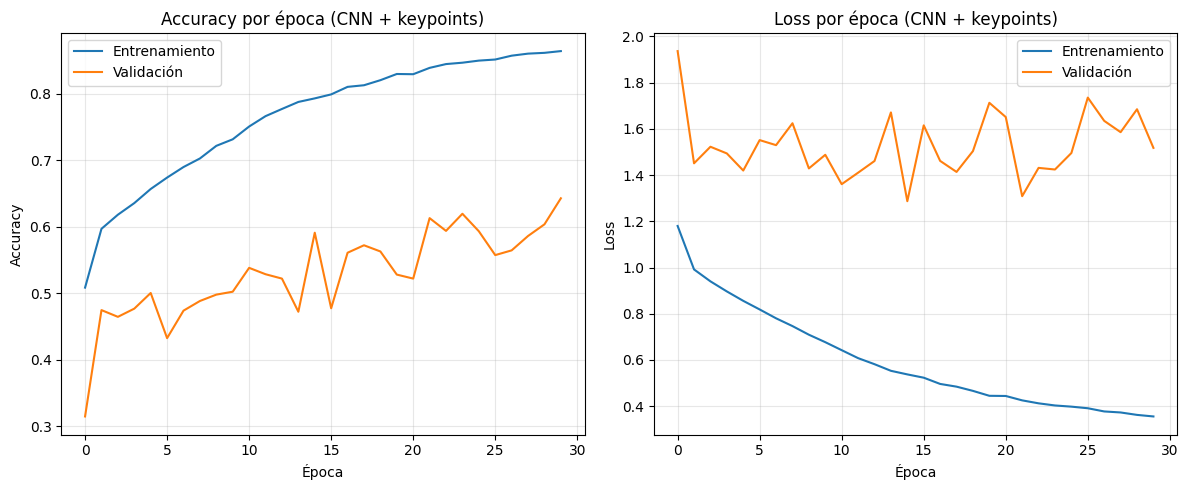

In [6]:
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
model.save(MODEL_PATH)
print(f"Modelo guardado en {MODEL_PATH}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history["accuracy"], label="Entrenamiento")
axes[0].plot(history.history["val_accuracy"], label="Validación")
axes[0].set_title("Accuracy por época (CNN + keypoints)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Entrenamiento")
axes[1].plot(history.history["val_loss"], label="Validación")
axes[1].set_title("Loss por época (CNN + keypoints)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("model_results/cnn/cnn_training_curves.png", dpi=150)
plt.show()

Resultados por clase

287/287 [==============================] - 1s 4ms/step
              precision    recall  f1-score   support

       Angry       0.75      0.84      0.79      1540
        Fear       0.72      0.69      0.70      1413
       Happy       0.91      0.95      0.93      3105
         Sad       0.77      0.80      0.79      1755
     Suprise       0.89      0.67      0.76      1369

    accuracy                           0.82      9182
   macro avg       0.81      0.79      0.79      9182
weighted avg       0.82      0.82      0.82      9182



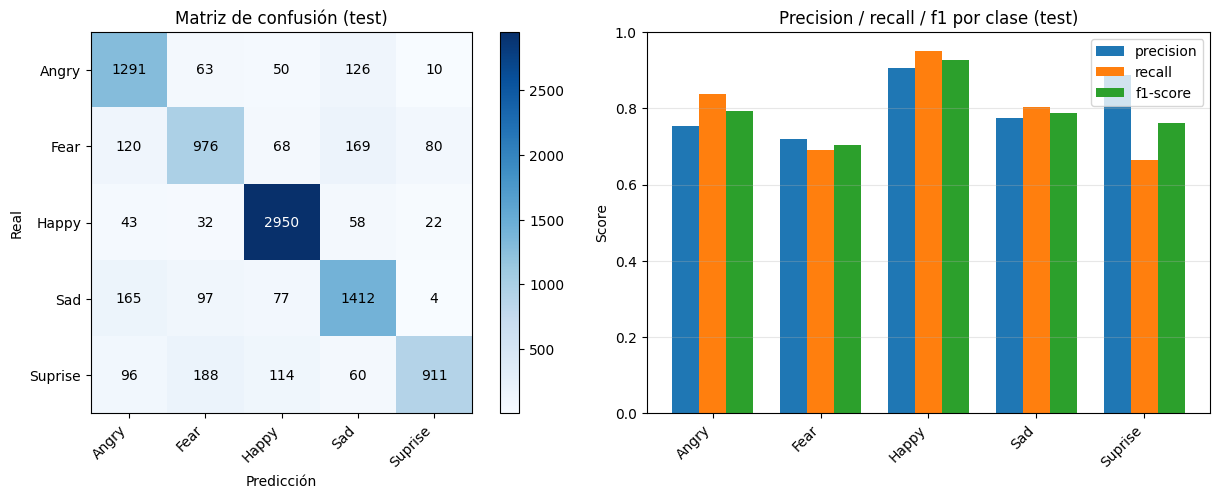

In [ ]:
y_pred_idx = np.argmax(model.predict([X_test_img, X_test_geo]), axis=1)
y_true_idx = np.argmax(y_test, axis=1)
y_pred_labels = [CLASSES[i] for i in y_pred_idx]
y_true_labels = [CLASSES[i] for i in y_true_idx]

report = classification_report(
    y_true_labels, y_pred_labels, labels=CLASSES, target_names=CLASSES, output_dict=True
)
print(classification_report(y_true_labels, y_pred_labels, labels=CLASSES, target_names=CLASSES))

cm = confusion_matrix(y_true_labels, y_pred_labels, labels=CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks(range(len(CLASSES)))
axes[0].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[0].set_yticks(range(len(CLASSES)))
axes[0].set_yticklabels(CLASSES)
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Real")
axes[0].set_title("Matriz de confusión (test)")
threshold = cm.max() / 2
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        color = "white" if cm[i, j] > threshold else "black"
        axes[0].text(j, i, cm[i, j], ha="center", va="center", color=color)
fig.colorbar(im, ax=axes[0])

metrics = ["precision", "recall", "f1-score"]
x = np.arange(len(CLASSES))
width = 0.25
for i, metric in enumerate(metrics):
    values = [report[label][metric] for label in CLASSES]
    axes[1].bar(x + (i - 1) * width, values, width, label=metric)
axes[1].set_xticks(x)
axes[1].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Score")
axes[1].set_title("Precision / recall / f1 per class (test)")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

fig.tight_layout()
fig.savefig("model_results/cnn/cnn_per_class_results.png", dpi=150)
plt.show()
